# NN_L12_perplexity_size

**Perplexity of Qwen2.5-0.5B, 1.5B and 3B on 40 ECB speeches of 2022-2023 and 40 speeches from July 2025 (first 1,024 tokens), and the slope of log loss on log parameters.**

Neural Networks and Deep Learning (NN), Lecture 12 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L12/NN_L12_perplexity_size/NN_L12_perplexity_size.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

perplexity 0.5B, 2022-2023 = 13.88   [ppl.05B.old]
perplexity 0.5B, from July 2025 = 14.71   [ppl.05B.new]
perplexity 1.5B, 2022-2023 = 9.99   [ppl.15B.old]
perplexity 1.5B, from July 2025 = 10.63   [ppl.15B.new]
perplexity 3B, 2022-2023 = 8.9   [ppl.3B.old]
perplexity 3B, from July 2025 = 9.43   [ppl.3B.new]
slope of log loss on log parameters = -0.1   [ppl_slope]


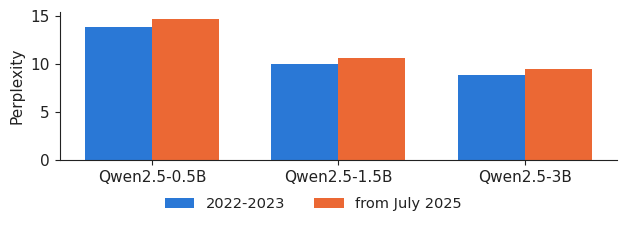

In [3]:
RES = REPO + 'lectures/L12/results/'
import json, urllib.request
def load_json(name):
    p = RES + name
    return json.load(open(p)) if os.path.exists(p) else json.load(urllib.request.urlopen(p))
J = load_json('lm_outputs.json')
nll, P = J['ppl_nll'], J['params_b']
sizes = ['0.5B', '1.5B', '3B']
for s in sizes:
    show('ppl.' + s.replace('.', '') + '.old', f'perplexity {s}, 2022-2023', round(float(np.exp(nll[s]['old'])), 2))
    show('ppl.' + s.replace('.', '') + '.new', f'perplexity {s}, from July 2025', round(float(np.exp(nll[s]['new'])), 2))
b = np.polyfit(np.log([P[s] for s in sizes]), np.log([nll[s]['new'] for s in sizes]), 1)[0]
show('ppl_slope', 'slope of log loss on log parameters', round(float(b), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.3))
ax.bar(np.arange(3) - 0.18, [np.exp(nll[s]['old']) for s in sizes], 0.36, color=PAL['data'], label='2022-2023')
ax.bar(np.arange(3) + 0.18, [np.exp(nll[s]['new']) for s in sizes], 0.36, color=PAL['model'], label='from July 2025')
ax.set_xticks(range(3))
ax.set_xticklabels(['Qwen2.5-' + s for s in sizes])
ax.set_ylabel('Perplexity')
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('perplexity_size.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()